# 6. Image compositing for AR effects

[All tutorials](https://github.com/bateni1380/landpy/tree/master/tutorials) · [Open in Colab](https://colab.research.google.com/github/bateni1380/landpy/blob/master/tutorials/6-image-compositing.ipynb)

## Goal

Place a transparent overlay into a rectangular or perspective region using the original implant-image idea.

## Setup

Run every cell in order. Python 3.10+ is required; use Python 3.10–3.13 for TensorFlow examples. The first cell installs the pinned release if needed. A CPU is enough.

In [1]:
import importlib.metadata
import subprocess
import sys
try:
    installed = importlib.metadata.version('landpy')
except importlib.metadata.PackageNotFoundError:
    installed = None
if installed != '0.1.0':
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'landpy==0.1.0'])
import numpy as np
import matplotlib.pyplot as plt
from landpy import ImageLand, MarksLand, SquareMarks, QuadMarks, DualMarks, HeatLand, Filter, Debugger
plt.rcParams.update({'figure.figsize': (9, 4), 'axes.titlesize': 12})

## Steps

### 1. Make a transparent image overlay

Alpha is a separate uint8 channel. A value of 0 is transparent, 255 is opaque. The blend ratio multiplies source alpha.

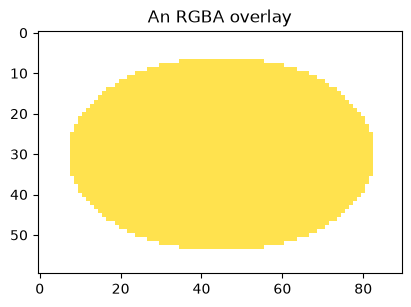

In [2]:
rows, columns = np.indices((120, 180))
pixels = np.stack((columns / 179, rows / 119, np.full(rows.shape, .35)), axis=-1)
image = ImageLand(pixels)

sticker = np.zeros((60, 90, 4), dtype=np.uint8)
y, x = np.indices(sticker.shape[:2])
inside = ((y-30)/24)**2 + ((x-45)/38)**2 < 1
sticker[inside] = [255, 220, 40, 210]
ImageLand(sticker).show('An RGBA overlay')

### 2. Position an overlay

`src_land` names the destination region on the base image; `plant_land` selects the source region on the overlay. This historical naming is retained. Both accept rectangles or convex quads. The source image is unchanged.

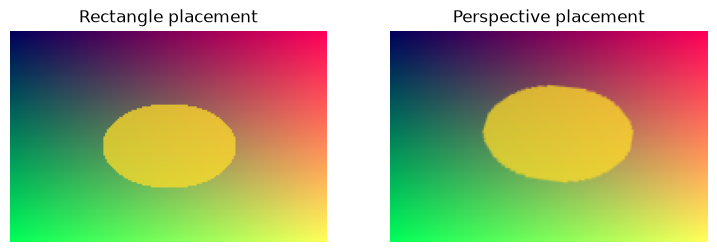

In [3]:
region = SquareMarks(35, 95, 45, 135, shape=image.shape)
placed = image.copy().implant_image(sticker, src_land=region, ratio=.9)
quad = QuadMarks((20, 55), (30, 150), (100, 140), (85, 35), shape=image.shape)
perspective = image.copy().implant_image(sticker, src_land=quad, ratio=.9)
fig, axes = plt.subplots(1, 2)
for ax, item, title in zip(axes, [placed, perspective], ['Rectangle placement', 'Perspective placement']):
    ax.imshow(item.get_image()); ax.set_title(title); ax.axis('off')
plt.show()

### 3. Compose with existing masks

Use landmark polygons to build a HeatLand and apply a color filter before compositing. The same workflow fits detected face regions in tutorial 8.

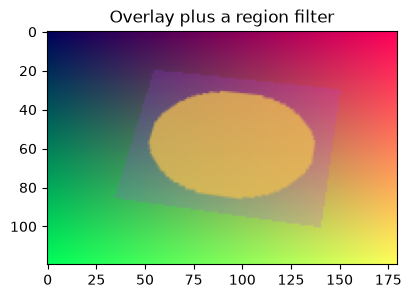

In [4]:
mask = quad.to_heat(.6)
result = perspective.copy().implant_filter(Filter('#aa44ff', .3), mask)
result.show('Overlay plus a region filter')

## Checks

In [5]:
assert result.shape == image.shape
assert image.mode == 'RGB'
np.testing.assert_array_equal(placed.get_image()[0, 0], image.get_image()[0, 0])
np.testing.assert_array_equal(image.copy().implant_image(sticker, ratio=0).get_image(), image.get_image())

## Next steps

Continue with tutorial 7 in the [tutorial index](https://github.com/bateni1380/landpy/tree/master/tutorials).